# Willsey 2025 source data

This notebook inspects the public Dryad release behind the finger-decoding and quadcopter paper. A single BrainGate2 participant, T5, controlled a virtual hand through an intracortical decoder that read spike-band power from two 96-channel arrays in the hand knob of left precentral gyrus. Three finger groups were controlled (thumb, index-middle, ring-little), and because the thumb moves in two dimensions the task has four degrees of freedom.

One `.mat` file is one task block, not one recording day. Blocks are the right unit here because the task variant and the online decoder change from block to block within a day.

The release holds three kinds of block:

- **closed loop** (58 blocks, seven days): the decoder drives the hand, and the participant acquires target postures.
- **open loop** (2 blocks): the task drives the hand, and the participant attempts a cued single-joint movement.
- **quadcopter** (1 block): a saved flight path with no neural data at all.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

from neuralshed.datasets.willsey_2025 import utils

## Inventory

`utils.list_blocks` walks the release and returns one `BlockRef` per file, in recording order. The block kind comes from the folder, except for the quadcopter block, which sits among the closed-loop folders and is named explicitly in `utils.QUADCOPTER_BLOCK`.

In [2]:
blocks = utils.list_blocks()
sessions = utils.list_sessions()

print(f"data directory: {utils.DEFAULT_DATA_DIR}")
print(f"recording days: {len(sessions)}  ({sessions[0]} to {sessions[-1]})")
print(f"blocks: {len(blocks)}")
print("blocks per kind:", Counter(block.kind for block in blocks))

data directory: /media/heberto/Expansion/tether/datasets/willsey_2025/data/Data
recording days: 8  (t5.2023.03.09 to t5.2023.07.12)
blocks: 61
blocks per kind: Counter({'closed_loop': 58, 'open_loop': 2, 'quadcopter': 1})


In [3]:
# One row per recording day. Trials exist only in the closed-loop blocks.
print(f"{'session':16s} {'blocks':>6s} {'minutes':>8s} {'trials':>7s}  tasks")
for session, day_blocks in utils.session_blocks().items():
    recorded = [b for b in day_blocks if b.kind != utils.KIND_QUADCOPTER]
    minutes = sum(utils.bin_times(b)[-1] for b in recorded) / 60
    trials = sum(
        len(utils.trial_windows(b)) for b in day_blocks if b.kind == utils.KIND_CLOSED_LOOP
    )
    tasks = ", ".join(sorted({b.task_label for b in day_blocks}))
    print(f"{session:16s} {len(day_blocks):6d} {minutes:8.1f} {trials:7d}  {tasks}")

session          blocks  minutes  trials  tasks
t5.2023.03.09         1      4.4     101  Finger target acquisition (closed loop)
t5.2023.03.14         1      5.7     101  Finger target acquisition (closed loop)


t5.2023.03.16         7     21.8     346  Finger target acquisition (closed loop)
t5.2023.03.21         2      9.7     318  Finger target acquisition (closed loop)


t5.2023.03.23        14     40.9     688  Finger target acquisition (closed loop)


t5.2023.04.06        15     35.1     638  Cued single-degree-of-freedom movement (open loop), Finger target acquisition (closed loop)


t5.2023.04.13        20     37.4     980  Finger target acquisition (closed loop)
t5.2023.07.12         1      0.0       0  Quadcopter flight path (no recording)


## What one block file holds

Each closed-loop file is a flat MATLAB v5 file holding two redis streams that were recorded side by side: the binned neural features and the game state. `utils.load_block` normalizes the field names, since the open-loop files drop the `binned_` prefix and carry no decoder output.

In [4]:
example = next(b for b in blocks if b.kind == utils.KIND_CLOSED_LOOP)
raw = utils.load_block(example)

print(f"block {example.label}  ({example.path.name})")
for name, value in raw.items():
    if isinstance(value, np.ndarray):
        print(f"  {name:20s} {str(value.shape):16s} {value.dtype}")
    else:
        print(f"  {name:20s} {value}")

block t5.2023.03.09_block18  (t5_t5.2023.03.09_Data_RedisMat_20230309_150822_(18).mat)
  spike_band_power     (5274, 192)      float32
  neural_clock         (5274,)          int64
  task_clock           (322876,)        int64
  target               (322876, 6)      float64
  hand_color           (322876,)        int64
  position             (322876, 6)      float64
  neural_xpc_clock     (5274,)          int64
  holdTime             0.5
  fn_hold_threshold    0.1


## The two streams and their shared clock

The streams run at different rates and are only relatable through the unix-millisecond `redisClock` they both carry. The neural stream is binned at 50 ms (20 Hz) and the task stream runs at roughly 1.3 kHz.

There is one quirk worth seeing directly: the **first 76 to 88 bins of every block are spaced 20 ms rather than 50 ms**. The authors drop the first 80 before normalizing, calling them noisy. They are not noise, though, and the next cell shows what they actually are.

In [5]:
neural_clock = raw["neural_clock"]
task_clock = raw["task_clock"]

print(f"neural bins: {neural_clock.size}  span {(neural_clock[-1] - neural_clock[0]) / 1000:.1f} s")
print(f"task samples: {task_clock.size}  span {(task_clock[-1] - task_clock[0]) / 1000:.1f} s")
print(f"task rate: {task_clock.size / ((task_clock[-1] - task_clock[0]) / 1000):.0f} Hz")
print()
print("neural bin intervals (ms), first 90 bins:", Counter(np.diff(neural_clock[:91]).tolist()))
print("neural bin intervals (ms), rest of block:", Counter(np.diff(neural_clock[90:]).tolist()).most_common(4))

neural bins: 5274  span 261.2 s
task samples: 322876  span 256.5 s
task rate: 1259 Hz

neural bin intervals (ms), first 90 bins: Counter({20: 48, 19: 16, 21: 15, 50: 4, 51: 2, 22: 1, 18: 1, 23: 1, 17: 1, 49: 1})
neural bin intervals (ms), rest of block: [(50, 3103), (49, 1025), (51, 1022), (52, 13)]


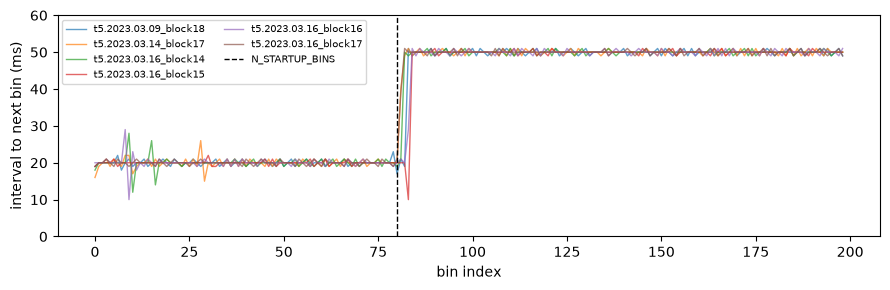

In [6]:
# The switch from 20 ms to 50 ms spacing, shown for the first 200 bins of six blocks.
fig, ax = plt.subplots(figsize=(9, 3))
for block in [b for b in blocks if b.kind == utils.KIND_CLOSED_LOOP][:6]:
    intervals = np.diff(utils.load_block(block)["neural_clock"][:200])
    ax.plot(intervals, lw=1, alpha=0.7, label=block.label)
ax.axvline(utils.N_STARTUP_BINS, color="k", ls="--", lw=1, label="N_STARTUP_BINS")
ax.set(xlabel="bin index", ylabel="interval to next bin (ms)", ylim=(0, 60))
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()

### What the 20 ms prefix really is

Spike-band power here is **summed over the bin, not averaged**, so a 20 ms bin simply carries 40% of what a 50 ms bin carries. Rescaling the prefix by 50/20 recovers the bins that follow it, which is the test below.

That matters twice over. It explains why the authors drop the prefix before z-scoring, since the narrower bins drag the per-channel mean and standard deviation down. And it establishes that the feature is extensive, so any rebinning of this stream has to sum rather than average.

20 ms bins opening this block: 83
raw prefix mean / rest of block: 0.406   (20/50 = 0.400)
level ratio after rescaling by 50/20: 0.992
per-channel corr(prefix x 2.5, next 400 bins): 0.872


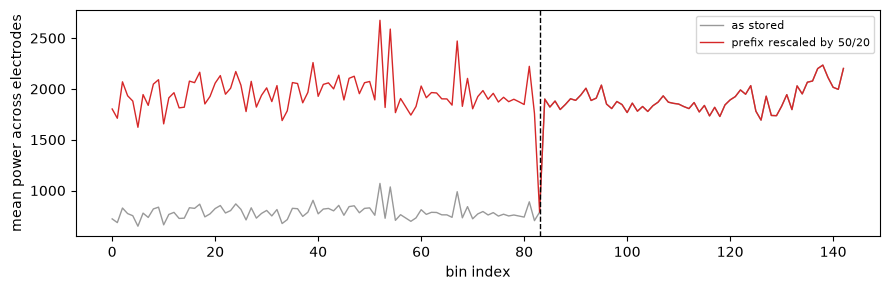

In [7]:
power = utils.get_neural(example)  # trimmed to the 192 real electrodes
switch = int(np.argmax(np.diff(neural_clock) > 35))
prefix, following = power[:switch], power[switch:switch + 400]

print(f"20 ms bins opening this block: {switch}")
print(f"raw prefix mean / rest of block: {prefix.mean() / power[switch:].mean():.3f}   (20/50 = 0.400)")
print(f"level ratio after rescaling by 50/20: {prefix.mean() * 2.5 / following.mean():.3f}")
print(f"per-channel corr(prefix x 2.5, next 400 bins): {np.corrcoef(prefix.mean(0) * 2.5, following.mean(0))[0, 1]:.3f}")

# The step at the changeover, raw and rescaled.
span = slice(0, switch + 60)
per_bin = power[span].mean(axis=1)
rescaled = np.where(np.arange(span.stop) < switch, per_bin * 2.5, per_bin)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(per_bin, lw=1, color="0.6", label="as stored")
ax.plot(rescaled, lw=1, color="C3", label="prefix rescaled by 50/20")
ax.axvline(switch, color="k", ls="--", lw=1)
ax.set(xlabel="bin index", ylabel="mean power across electrodes")
ax.legend(fontsize=8)
plt.tight_layout()

## Neural features

The neural stream is spike-band power, which the source names `hlfp` (high-frequency LFP). It ships 256 columns, of which only the first 192 are electrodes: columns 192 to 255 are exactly zero in every released block, and `utils.get_neural` trims them off. The Supplementary Methods give the chain: a 250 Hz digital high-pass, common average referencing, then the sum of the squared magnitude over each 50 ms window, sampled at 30 kHz. So the unit is microvolts squared, and because the bin sums rather than averages the quantity is extensive.

In [8]:
power = utils.get_neural(example)
times = utils.bin_times(example)

print(f"spike-band power: {power.shape} {power.dtype}")
print(f"value range: {power.min():.1f} to {power.max():.1f}, per-channel mean {power.mean():.0f}")
print(f"channels that never move: {(power.std(axis=0) == 0).sum()}")
print(f"stored but empty columns trimmed: {utils.N_CHANNELS_STORED - utils.N_CHANNELS}")

spike-band power: (5274, 192) float32
value range: 237.9 to 120740.4, per-channel mean 1915
channels that never move: 0
stored but empty columns trimmed: 64


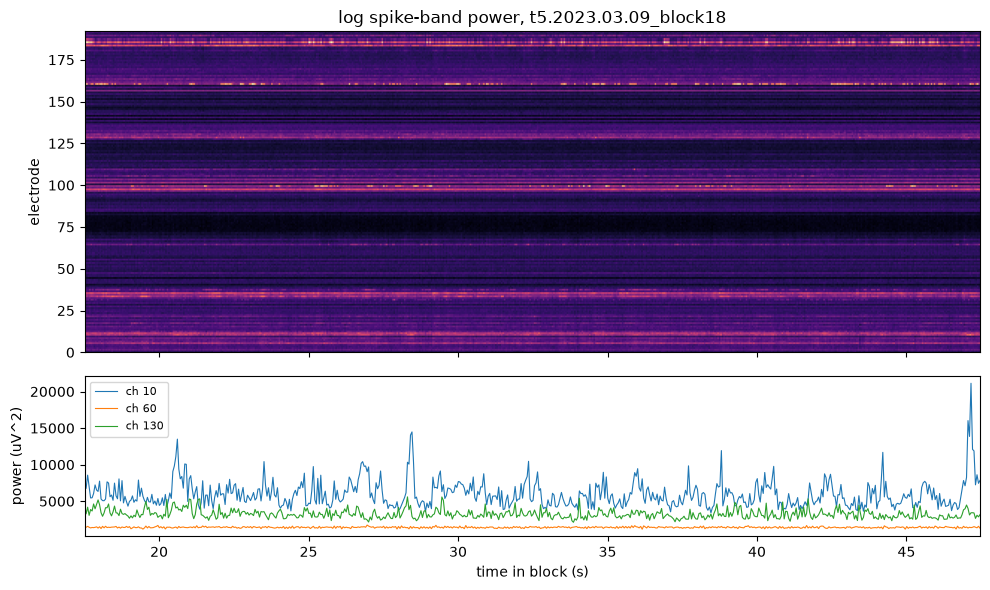

In [9]:
# 30 s of the array, and three channels at full resolution underneath.
window = slice(400, 400 + int(30 * utils.FS))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[2, 1])

axes[0].imshow(
    np.log1p(power[window].T),
    aspect="auto",
    origin="lower",
    cmap="magma",
    extent=(times[window][0], times[window][-1], 0, utils.N_CHANNELS),
)
axes[0].set(ylabel="electrode", title=f"log spike-band power, {example.label}")

for channel in (10, 60, 130):
    axes[1].plot(times[window], power[window, channel], lw=0.8, label=f"ch {channel}")
axes[1].set(xlabel="time in block (s)", ylabel="power (uV^2)")
axes[1].legend(fontsize=8)
plt.tight_layout()

## The finger streams

The position and target streams carry six columns, described by the source README as the two thumb degrees of freedom followed by index, middle, ring and little. Only four of them are independent, because index and middle move as one group and so do ring and little. The authors select columns `[0, 1, 2, 5]`, which `utils.DECODED_COLUMNS` reproduces.

Positions are a fraction of the range of motion: 0 is full flexion, 1 is full extension, and 0.5 is the neutral posture.

In [10]:
position = raw["position"]
print("stored columns:", utils.STORED_DIMS)
for i, j in [(2, 3), (4, 5)]:
    same = np.array_equal(position[:, i], position[:, j])
    print(f"  column {i} ({utils.STORED_DIMS[i]}) equals column {j} ({utils.STORED_DIMS[j]}): {same}")
print()
print("decoded degrees of freedom:", utils.DECODED_DIMS)
print("taken from columns:", utils.DECODED_COLUMNS)

stored columns: ('thumb_flexion', 'thumb_abduction', 'index', 'middle', 'ring', 'little')
  column 2 (index) equals column 3 (middle): True
  column 4 (ring) equals column 5 (little): True

decoded degrees of freedom: ('thumb_flexion', 'thumb_abduction', 'index_middle', 'ring_little')
taken from columns: (0, 1, 2, 5)


position on bins: (5274, 4)  target on bins: (5274, 4)


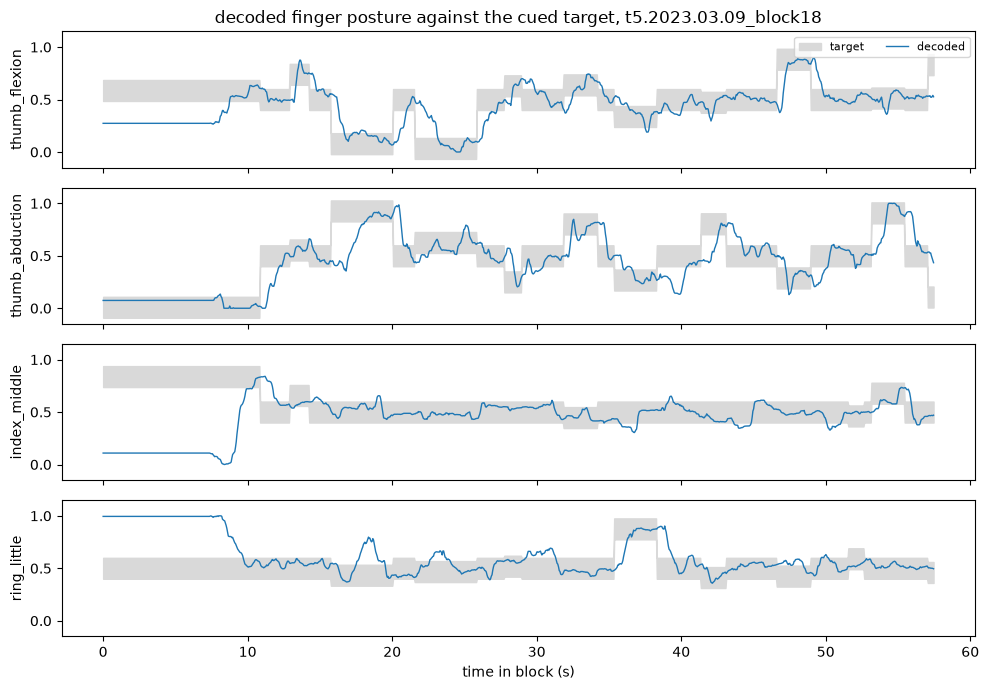

In [11]:
# Both finger streams resampled onto the neural bin times, which is how the authors
# align them (linear interpolation over the shared redis clock).
finger = utils.get_finger_position(example)
target = utils.get_finger_target(example)
print("position on bins:", finger.shape, " target on bins:", target.shape)

show = slice(0, int(60 * utils.FS))
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for k, (ax, dim) in enumerate(zip(axes, utils.DECODED_DIMS)):
    ax.fill_between(
        times[show],
        target[show, k] - utils.TARGET_HALF_WIDTH,
        target[show, k] + utils.TARGET_HALF_WIDTH,
        color="0.85",
        label="target",
    )
    ax.plot(times[show], finger[show, k], color="C0", lw=1, label="decoded")
    ax.set(ylabel=dim, ylim=(-0.15, 1.15))
axes[0].legend(fontsize=8, loc="upper right", ncol=2)
axes[0].set_title(f"decoded finger posture against the cued target, {example.label}")
axes[-1].set_xlabel("time in block (s)")
plt.tight_layout()

## Trials

The trial marker is the hand colour. In a closed-loop block it is 2 almost everywhere and flashes to 1 for about 10 ms at the moment the target is acquired, so a trial runs from the end of one flash to the start of the next. That is the edge pairing `t5_parse.m` uses, and `utils.trial_windows` reproduces it in neural-bin indices.

A trial ends when every controlled degree of freedom has been held inside its target for 500 ms, or when 10 s elapse.

In [12]:
color = raw["hand_color"]
print("hand colour values:", Counter(color.tolist()))

# Run lengths of the colour-1 flash, in milliseconds of the shared redis clock.
edges = np.flatnonzero(np.diff(color) != 0) + 1
bounds = np.concatenate(([0], edges, [color.size]))
flashes = [
    task_clock[stop - 1] - task_clock[start]
    for start, stop in zip(bounds[:-1], bounds[1:])
    if color[start] == utils.COLOR_ACQUIRED
]
print(f"the code-1 flash lasts a median of {np.median(flashes):.0f} ms, shorter than one 50 ms bin")

windows = utils.trial_windows(example)
targets = utils.trial_targets(example)
print(f"\ntrials in this block: {len(windows)}")
print("first three (start bin, stop bin):", windows[:3])

hand colour values: Counter({2: 321540, 1: 1336})
the code-1 flash lasts a median of 9 ms, shorter than one 50 ms bin

trials in this block: 101
first three (start bin, stop bin): [(197, 267), (267, 308), (308, 335)]


first ten targets, R = return to neutral: .R.R.R.R.R
return-to-neutral trials in this block: 50%


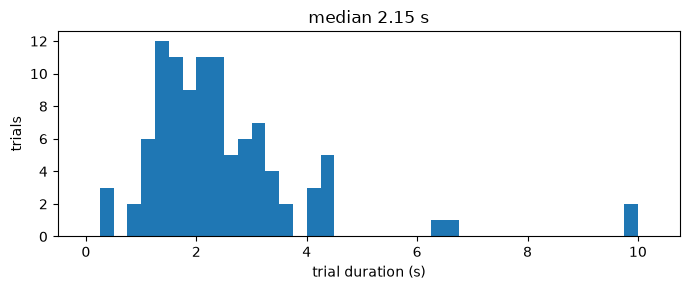

In [13]:
# Targets alternate between a randomly placed posture and a return to neutral.
is_rest = np.all(targets == utils.POSITION_NEUTRAL, axis=1)
print("first ten targets, R = return to neutral:", "".join("R" if r else "." for r in is_rest[:10]))
print(f"return-to-neutral trials in this block: {is_rest.mean():.0%}")

durations = np.array([times[stop - 1] - times[start] for start, stop in windows])
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(durations, bins=np.arange(0, 10.5, 0.25), color="C0")
ax.set(xlabel="trial duration (s)", ylabel="trials", title=f"median {np.median(durations):.2f} s")
plt.tight_layout()

## Task variants across blocks

Two variants are interleaved. In the four-degree-of-freedom task all four dimensions receive targets. In the two-degree-of-freedom task the thumb's abduction and the ring-little group are pinned at neutral, and only thumb flexion and the index-middle group are cued. `utils.target_dof` recovers which variant a block ran by asking which target columns vary.

What the data cannot tell you is which **decoder** was running. A four-degree-of-freedom decoder driving the two-degree-of-freedom task looks identical to a genuine two-degree-of-freedom decoder, because the game pins the unused dimensions either way. Those labels exist only in the authors' notebook and are transcribed into `utils.BLOCK_LABELS`.

In [14]:
closed = [b for b in blocks if b.kind == utils.KIND_CLOSED_LOOP]
print("blocks by number of cued degrees of freedom:", Counter(len(utils.target_dof(b)) for b in closed))
print()
print(f"{'block':26s} {'task DoF':>8s}  {'decoder DoF':>11s}  {'new targets':>11s}")
for block in closed[26:34]:
    labels = utils.BLOCK_LABELS.get(block.label, {})
    print(
        f"{block.label:26s} {len(utils.target_dof(block)):8d}"
        f"  {str(labels.get('decoder_dof', '-')):>11s}  {str(labels.get('new_targets', '-')):>11s}"
    )

blocks by number of cued degrees of freedom: Counter({4: 36, 2: 22})

block                      task DoF  decoder DoF  new targets
t5.2023.04.06_block16             2            -            -
t5.2023.04.06_block30             4            4            -
t5.2023.04.06_block31             2            4            -
t5.2023.04.06_block33             4            4            -
t5.2023.04.06_block34             2            4            -
t5.2023.04.06_block41             2            -            -
t5.2023.04.06_block42             4            4            -
t5.2023.04.06_block43             2            4            -


## Open-loop blocks

The two open-loop blocks are the tuning experiment. The task drives the hand while the participant attempts a cued movement. A cued posture is held for 3 s and alternates with 3 s of rest, and inside every 3 s window a 1 s preparation phase (colour 1) is followed by a 2 s go phase (colour 2). There are nine conditions: rest, plus each of the four degrees of freedom driven to full flexion or full extension.

`utils.cue_windows` returns the go phases with their condition name.

In [15]:
open_blocks = [b for b in blocks if b.kind == utils.KIND_OPEN_LOOP]
cues = [w for block in open_blocks for w in utils.cue_windows(block)]
print(f"open-loop blocks: {len(open_blocks)}, go phases: {len(cues)}")
print("go phase duration (bins):", Counter(stop - start for start, stop, _ in cues).most_common(3))
print()
for condition, n in sorted(Counter(name for _, _, name in cues).items()):
    print(f"  {condition:24s} {n:3d}")

open-loop blocks: 2, go phases: 200
go phase duration (bins): [(40, 193), (39, 6), (41, 1)]

  index_middle-extend       11
  index_middle-flex         11
  rest                     112
  ring_little-extend        10
  ring_little-flex          12
  thumb_abduction-extend    12
  thumb_abduction-flex      10
  thumb_flexion-extend      10
  thumb_flexion-flex        12


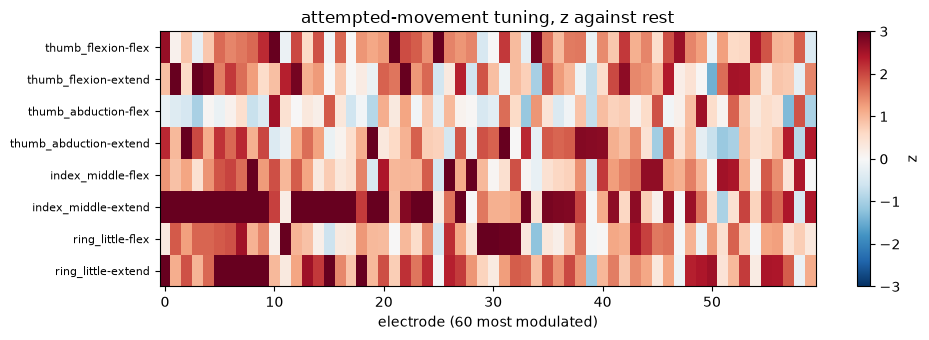

In [16]:
# Movement tuning: mean power over each 2 s go phase, z-scored per channel against
# the rest phases, then averaged within condition.
trials, labels = [], []
for block in open_blocks:
    block_power = utils.get_neural(block)
    for start, stop, condition in utils.cue_windows(block):
        trials.append(block_power[start:stop].mean(axis=0))
        labels.append(condition)
trials, labels = np.array(trials), np.array(labels)

rest = trials[labels == "rest"]
z = (trials - rest.mean(axis=0)) / rest.std(axis=0)

conditions = [c for c in utils.OPEN_LOOP_CONDITIONS.values() if c != "rest"]
tuning = np.array([z[labels == c].mean(axis=0) for c in conditions])
order = np.argsort(np.abs(tuning).max(axis=0))[::-1][:60]

fig, ax = plt.subplots(figsize=(10, 3.5))
image = ax.imshow(tuning[:, order], aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set(yticks=range(len(conditions)), xlabel="electrode (60 most modulated)", title="attempted-movement tuning, z against rest")
ax.set_yticklabels(conditions, fontsize=8)
fig.colorbar(image, ax=ax, label="z")
plt.tight_layout()

## The quadcopter flight path

The last block is not a recording. It holds one saved flight through the obstacle course, as `x`, `y` and `z` with no clock and no documented sample rate, so the authors plot it against sample index. `z` points down, so elevation is `-z`, which their `PlotFlightPath.m` confirms by plotting `x, y, -z` against course rings centred at `z = +14.91`.

flight path: (81601, 3)
x range: -194.6 to -102.8
y range: 0.3 to 44.4
elevation (-z) range: 10.0 to 30.9


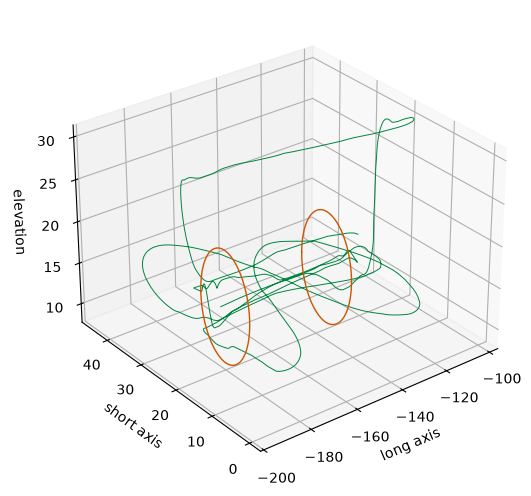

In [17]:
path = utils.quadcopter_path()
print("flight path:", path.shape)
print("x range:", path[:, 0].min().round(1), "to", path[:, 0].max().round(1))
print("y range:", path[:, 1].min().round(1), "to", path[:, 1].max().round(1))
print("elevation (-z) range:", (-path[:, 2]).min().round(1), "to", (-path[:, 2]).max().round(1))

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
ax.plot(path[:, 0], path[:, 1], -path[:, 2], lw=0.7, color="#00843D")
for centre in ([-134.13, 20.80, 14.91], [-178.77, 20.80, 14.91]):
    angle = np.linspace(0, 2 * np.pi, 200)
    ax.plot(
        np.full_like(angle, centre[0]),
        centre[1] + 6.75 * np.cos(angle),
        centre[2] + 6.75 * np.sin(angle),
        color="#CC5500",
        lw=1,
    )
ax.set(xlabel="long axis", ylabel="short axis", zlabel="elevation")
ax.view_init(elev=29, azim=-128)
plt.tight_layout()

## Summary

- 61 released blocks: 58 closed loop, 2 open loop, 1 quadcopter flight path.
- Neural features are spike-band power on 192 electrodes in 50 ms bins (20 Hz), in microvolts squared, summed over the bin rather than averaged, with the first roughly 82 bins of each block spaced 20 ms instead of 50 ms.
- Behaviour is four independent degrees of freedom (thumb flexion, thumb abduction, index-middle, ring-little) stored across six columns, as a fraction of the range of motion.
- Trials come from the hand-colour flash and alternate a random target with a return to neutral. There are 3,172 across 144 minutes of closed-loop recording.
- The task's degree-of-freedom count is recoverable from the data, the online decoder's is not, and is carried in `utils.BLOCK_LABELS`.